# 10-year all-cause mortality risk from a routine health exam

**Question.** Given the information collected in a single NHANES exam (demographics, body measurements, blood pressure, and standard blood labs), how well can we predict whether an adult will die from any cause within 10 years?

**Tougher follow-up question.** Age alone is a strong predictor of death. *How much do the clinical measurements add beyond age?* Every model below is compared against an age-only logistic regression, not just against the others.

**Data.** NHANES 1999–2018 participants aged 18+, linked to the CDC National Death Index (2019 public-use release). See `01_data_acquisition.ipynb` for how the files were downloaded and merged.

All modelling code lives in `src/mortality/` so this notebook can focus on the analysis.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import display

from mortality import data, train
from mortality.evaluate import paired_auc_difference

pd.set_option("display.precision", 3)

## 1. Cohort and outcome

The death index reports vital status and months of follow-up (through Dec 2019) for each participant. A 10-year label is defined as **died within 120 months** vs. **alive at 120 months**.

**Avoiding a labelling bias.** For survey cycles from 2009 on, follow-up ends before 10 years for some or all participants. Within those cycles, only the people who *died* early can be labelled at all; every 2011–2017 participant with a defined label is a death. The original course project kept these rows, which inflated the death rate and taught the model a spurious pattern. Here, only the cycles in which **every survivor was followed for the full 10 years** (1999–2007) are kept. The check is automatic, in `data.add_outcome`.

Other cleaning steps (in `data.clean_features`):
- NHANES "refused" / "don't know" codes (7, 9) set to missing
- diastolic BP readings of 0 (an NHANES measurement artefact) set to missing; the three BP readings averaged
- duplicate SI-unit lab columns dropped; HDL and glucose, which changed variable names between cycles, merged into one mg/dL column each

In [2]:
raw = data.load_raw()
df = data.load_modelling_table()
print(f"Raw linked records:        {len(raw):,}")
print(f"With a defined 10-yr label: {len(df):,}")
print(f"Died within 10 years:       {df['died'].sum():,} ({df['died'].mean():.1%})")
print(f"Survey cycles included:     {sorted(df['cycle_start'].unique())}")

Raw linked records:        26,453
With a defined 10-yr label: 12,418
Died within 10 years:       1,854 (14.9%)
Survey cycles included:     [np.int64(1999), np.int64(2001), np.int64(2003), np.int64(2005), np.int64(2007)]


In [3]:
age_band = pd.cut(df["age"], [17, 39, 54, 64, 74, 85], labels=["18–39", "40–54", "55–64", "65–74", "75–85"])
(df.groupby(age_band, observed=True)["died"]
   .agg(participants="size", ten_year_mortality="mean")
   .style.format({"ten_year_mortality": "{:.1%}", "participants": "{:,}"}))

,participants,ten_year_mortality
age,,
18–39,"4,607",1.3%
40–54,"2,917",5.5%
55–64,"1,782",15.0%
65–74,"1,612",26.6%
75–85,"1,500",62.6%


10-year mortality climbs from about 1% under 40 to more than 60% at 75+. This is why an age-only model is the right baseline: any model that just learns age will already look impressive.

In [4]:
df[data.ALL_FEATURES].isna().mean().sort_values(ascending=False).head(8).rename("share missing").to_frame()

,share missing
hdl,0.413
ldl,0.119
triglycerides,0.064
total_chol,0.062
dbp,0.059
glucose,0.055
leg_len_cm,0.053
sbp,0.051


Missingness is modest (12% or less) for every feature except **HDL cholesterol (≈41%)**. In 1999–2002, NHANES stored HDL under a different variable name that the acquisition step did not capture, so HDL is missing for those two cycles. Each pipeline imputes with the training-fold median **and** adds a missing-indicator column, so the model can learn from the fact that a value is missing (for example, a skipped fasting blood draw).

## 2. Experimental setup

| Choice | Why |
|---|---|
| Stratified 80/20 train/test split; the test set is touched once, at the end | gives an honest estimate of performance on unseen people |
| Positive class = **death** | the minority class (≈15%) is the one we care about catching |
| Every model is an sklearn `Pipeline` (impute → scale/encode → model) | preprocessing is fit inside each CV fold, so nothing leaks from validation data |
| Hyperparameters tuned with 5-fold randomized search scored by **PR AUC** | accuracy rewards predicting "survives" for everyone |
| Decision threshold picked on *out-of-fold training* predictions to catch 80% of deaths, then frozen | the threshold is never tuned on the test set |
| 1,000-sample bootstrap 95% CIs on all test metrics | shows whether differences between models are real |

Models, from simplest to most complex:
1. **Age only**: logistic regression on age
2. **Demographics**: + sex, race/ethnicity, education, smoking history
3. **All features (logistic)**: + body measurements, blood pressure, lipids, glucose, HbA1c
4. **Random forest** on all features
5. **XGBoost** on all features

In [5]:
exp = train.fit_all(train.split(df), n_iter=30)
print(f"\nTrain: {len(exp.y_train):,}   Test: {len(exp.y_test):,}   Test death rate: {exp.y_test.mean():.1%}")

fitted Age only (logistic)        {}


fitted Demographics (logistic)    {}


fitted All features (logistic)    {'C': 0.06672367170464207}


fitted Random forest              {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 11}


fitted XGBoost                    {'colsample_bytree': 0.767044709687721, 'learning_rate': 0.042734471318432575, 'max_depth': 2, 'min_child_weight': 19, 'reg_lambda': 0.3457997441375999, 'subsample': 0.6976502088991097}

Train: 9,934   Test: 2,484   Test death rate: 14.9%


## 3. Results on the held-out test set

In [6]:
table = train.results_table(exp)
cols = ["ROC AUC", "ROC AUC CI", "PR AUC", "PR AUC CI", "Brier",
        "Recall (deaths)", "Precision (deaths)", "Specificity"]
table[cols]

,ROC AUC,ROC AUC CI,PR AUC,PR AUC CI,Brier,Recall (deaths),Precision (deaths),Specificity
model,,,,,,,,
Age only (logistic),0.865,0.845–0.884,0.565,0.514–0.617,0.089,0.776,0.404,0.799
Demographics (logistic),0.877,0.858–0.895,0.606,0.556–0.657,0.086,0.765,0.436,0.826
All features (logistic),0.889,0.871–0.906,0.641,0.594–0.694,0.081,0.787,0.456,0.835
Random forest,0.883,0.864–0.901,0.631,0.580–0.680,0.083,0.768,0.466,0.845
XGBoost,0.892,0.874–0.909,0.651,0.601–0.699,0.081,0.774,0.474,0.850


In [7]:
gains = train.baseline_gains(exp)
est, lo, hi = paired_auc_difference(exp.y_test, exp.test_scores["XGBoost"], exp.test_scores["All features (logistic)"])
print(f"XGBoost vs. all-features logistic: ΔROC AUC = {est:+.3f} (95% CI {lo:+.3f} to {hi:+.3f})")
gains

XGBoost vs. all-features logistic: ΔROC AUC = +0.003 (95% CI -0.003 to +0.009)


,ΔROC AUC vs age only,95% CI
model,,
Demographics (logistic),0.012,+0.006 to +0.017
All features (logistic),0.024,+0.016 to +0.032
Random forest,0.018,+0.008 to +0.027
XGBoost,0.027,+0.017 to +0.036


**Reading the results**

- **Age alone gets you most of the way.** An age-only logistic regression reaches ROC AUC ≈ 0.87. All the clinical measurements together add **+0.02 to +0.03 AUC** (95% CIs exclude zero). The gain is real but small: most of the signal in a routine exam is age.
- **XGBoost and a regularized logistic regression are statistically tied** (ΔAUC ≈ +0.003, 95% CI spans zero). With equal performance, the logistic model is the better choice to deploy: it is transparent, has stable coefficients, and is easy to audit.
- **The practical gain is in precision.** At about the same recall (~77–79% of deaths caught), the full-feature models flag fewer survivors as high-risk than the age-only model. Precision on deaths rises from about 0.40 to 0.46–0.47 (see the table).
- For comparison, the original course project reported **F1 = 0.92**. That number was F1 for the *survivor* class (about 85% of people), which is easy to score well on. F1 for the death class is the one that matters, and it is around 0.59.

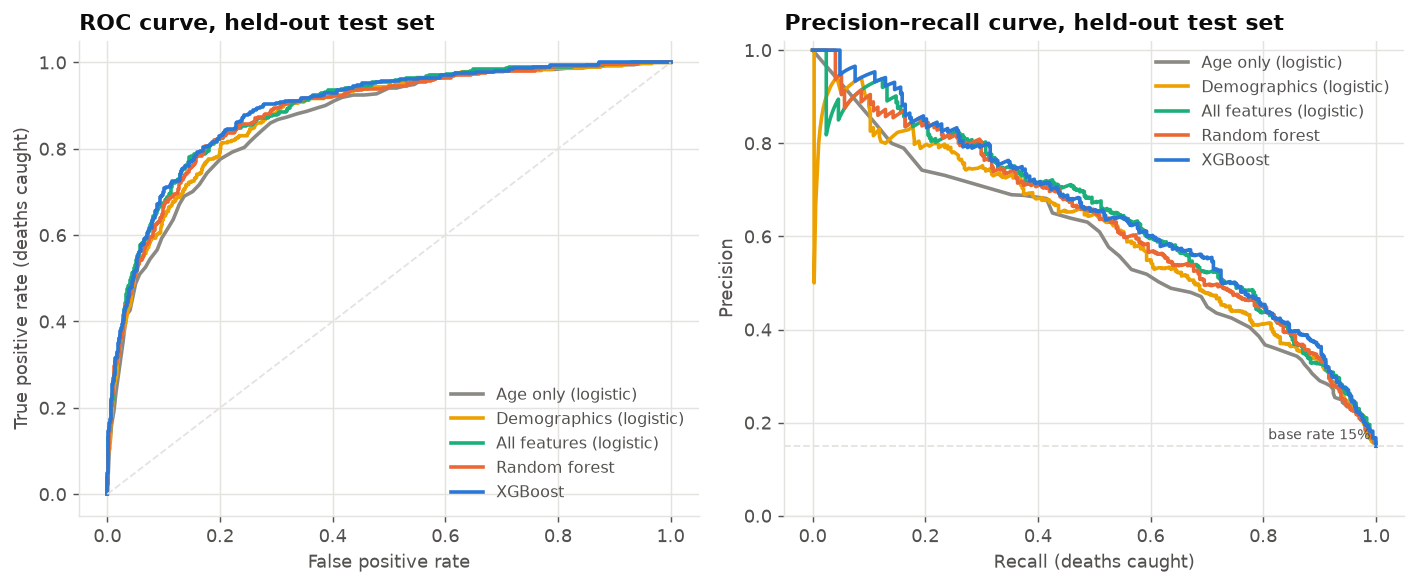

In [8]:
fig = train.plot_roc_pr(exp, train.FIG_DIR / "roc_pr_curves.png")

## 4. Are the probabilities trustworthy? (Calibration)

For a risk score, the predicted probabilities have to mean something: of the people given 30% risk, about 30% should die. Discrimination metrics like AUC don't check this.

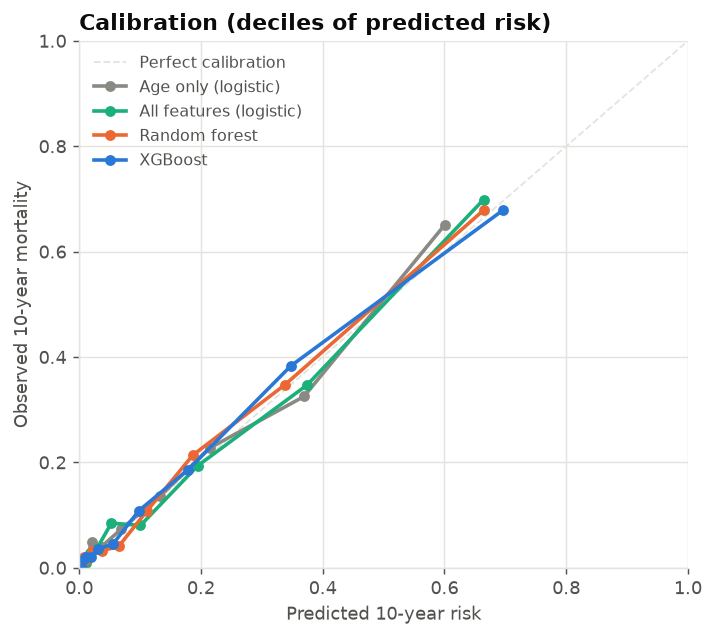

In [9]:
fig = train.plot_calibration(exp, ["Age only (logistic)", "All features (logistic)", "Random forest", "XGBoost"],
                             train.FIG_DIR / "calibration.png")

All four models track the diagonal closely across risk deciles (Brier ≈ 0.08), so the predicted probabilities can be read as actual risks. The only visible deviation is at the top decile, where XGBoost slightly over-predicts (predicted ≈ 0.70, observed ≈ 0.68).

## 5. Does the score separate long-term survival? (Kaplan–Meier)

The classifier was trained only on a yes/no 10-year label. Here we bin test-set participants into quintiles of predicted risk and plot survival over their **full** follow-up (up to about 20 years), information the model never saw.

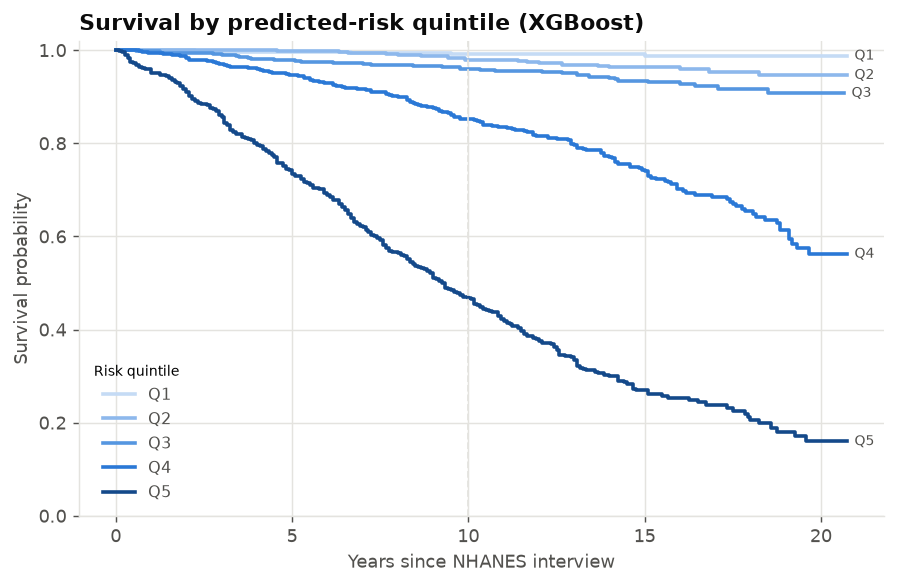

In [10]:
fig = train.plot_survival_by_risk(exp, "XGBoost", train.FIG_DIR / "survival_by_risk_quintile.png")

The quintiles separate cleanly and stay separated well past the 10-year mark: about 99% of the lowest-risk fifth are still alive at 20 years, versus about 16% of the highest-risk fifth. The score captures long-run mortality risk, not just a cut-off at 10 years.

## 6. What drives the predictions? (SHAP)

,mean |SHAP|
Age (years),1.562
Smoked 100+ cigarettes,0.236
Female,0.224
Waist circumference (cm),0.179
BMI,0.140
Education level,0.130
HbA1c (%),0.119
Arm circumference (cm),0.113
LDL cholesterol (mg/dL),0.109
Fasting glucose (mg/dL),0.109


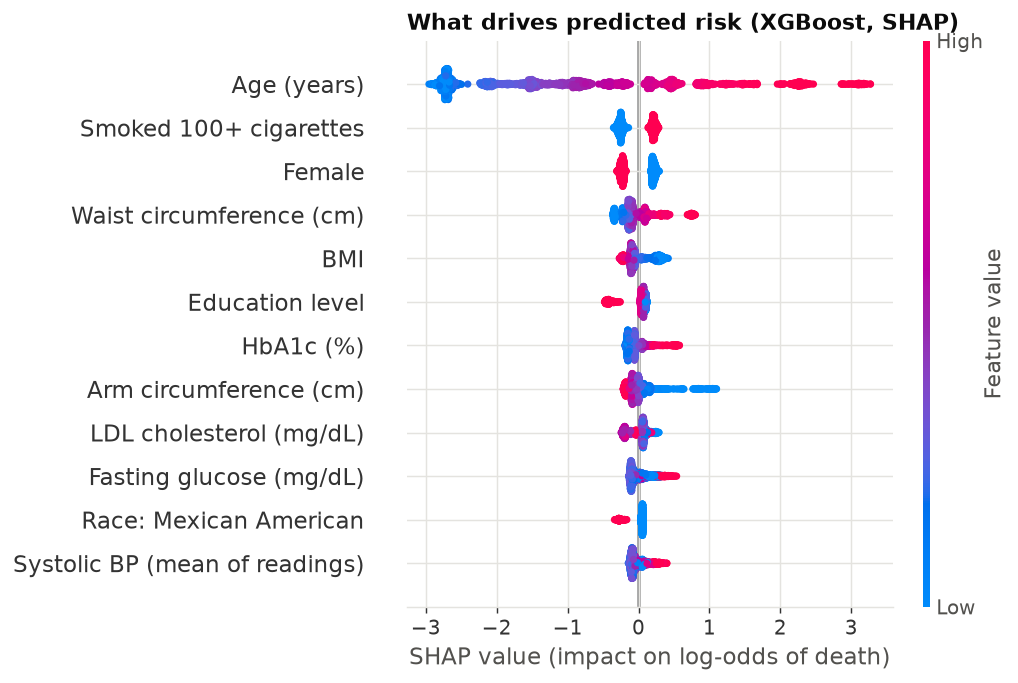

In [11]:
fig, importance = train.shap_summary(exp, "XGBoost", train.FIG_DIR / "shap_summary.png")
importance.head(10).rename("mean |SHAP|").to_frame()

- **Age** dominates: its average impact is about 6–7× that of the next feature.
- **Smoking history** and **sex** (male → higher risk) come next, consistent with the epidemiology literature.
- **Body shape matters more than body size.** A large **waist** (central adiposity) raises risk, but *higher* BMI and *larger* arm circumference *lower* it once waist is accounted for. Low BMI and thin arms are proxies for muscle loss and frailty in older adults; this is the well-documented "obesity paradox".
- **Higher education** is protective, a socioeconomic gradient visible even after accounting for health measures.
- **HbA1c, fasting glucose and systolic BP** raise risk at the high end, in line with diabetes and hypertension.
- **Low LDL cholesterol** is associated with *higher* risk. This is the known "reverse causation" pattern: serious illness lowers cholesterol, so it is not a sign that high cholesterol is protective. SHAP describes what the model learned, not causal effects.

## 7. Where does the model miss?

In [12]:
res = df.loc[exp.X_test.index, ["age", "female", "died"]].copy()
res["flagged"] = exp.test_scores["XGBoost"] >= exp.thresholds["XGBoost"]
res["age band"] = pd.cut(res["age"], [17, 39, 54, 64, 74, 85], labels=["18–39", "40–54", "55–64", "65–74", "75–85"])

def summarise(g):
    d = g[g["died"] == 1]
    return pd.Series({"deaths": len(d),
                      "deaths caught (recall)": d["flagged"].mean() if len(d) else np.nan,
                      "share of survivors flagged": g.loc[g["died"] == 0, "flagged"].mean()})

res.groupby("age band", observed=True).apply(summarise, include_groups=False)

,deaths,deaths caught (recall),share of survivors flagged
age band,,,
18–39,13.0,0.000,0.001
40–54,36.0,0.111,0.029
55–64,62.0,0.613,0.244
65–74,79.0,0.810,0.551
75–85,181.0,1.000,0.991


The errors follow age, as expected for an age-dominated model:
- **Under 55, about 9 in 10 deaths are missed.** These are rare, often sudden deaths (accidents, overdoses, acute events) that a cardiometabolic exam cannot see.
- **Over 75, nearly everyone is flagged**, including most survivors. The model has little ability to tell apart *which* older adults will die.

So the clinical features matter most for **ranking risk within an age group**, which is a good direction for future work (see below).

## 8. Limitations and next steps

- **Older cohort.** Requiring complete 10-year follow-up limits the data to 1999–2008 exams; risk patterns may have shifted since.
- **HDL missing for 1999–2002**, as noted above. Re-pulling the older variable (`LBDHDL`) is an easy fix.
- **No survey weights.** NHANES oversamples some groups. Results describe this sample, not U.S. adults as a whole; a weighted analysis (`WTMEC2YR`) would be needed for population estimates.
- **Censoring by exclusion.** A binary 10-year label discards the 2009–2018 participants entirely. A Cox or discrete-time survival model would use all of them.
- **Self-reported and single-visit features.** One BP reading session and one blood draw per person; no medications, diagnoses, or physical activity.
- **No external validation.** The test set comes from the same survey; performance on a clinical population could differ.

**Next steps:** survey-weighted evaluation; a survival model (Cox / XGBoost-AFT) using every participant; age-stratified models to improve ranking within older adults; adding the NHANES questionnaire data (diagnosed conditions, medications).